# LGD and EAD models against the benchmark evidence

**Question:** Do the findings of the loss given default and exposure at default benchmark studies, a low R-squared, a gain for non-linear models and the need for calibration, hold for the C08 and C09 models when the same families are run on data whose truth is known?

- **Level:** 3, comparison with published methods
- **Prerequisites:** notebooks 03, 05 and 06 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- state what the benchmark studies of loss given default and of exposure at default found, with their sources, and say which of the model families they compare Contraste implements and which it does not;
- run the non-linear against linear comparison on a sample whose truth is known, with the engine's rungs and a reference implementation of gradient-boosted trees, and read the R-squared and the calibration gap of each;
- check, on the six default cohorts of C08, the statements about R-squared, fractional logit against OLS and the sensitivity of the beta model to its endpoint adjustment;
- fit the factor, direct and utilisation-change EAD models on generated lines at three acceleration levels and compare them by the engine's own back-test;
- say what these checks do not show, so that a result on a charge-off indicator and on a generator is not read as a result on a bank.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2 scikit-learn==1.9.1
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

In [1]:
# Put the pipeline on the import path, import the packages and print their versions
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import lgd_models as lm
from riskvalidation.validation import lgd_ead as tests
from sklearn.ensemble import GradientBoostingRegressor

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c09 import estimators, generator
from pipeline.cases.c09 import models as ead_models

for name in ("riskvalidation", "numpy", "scikit-learn", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scikit-learn 1.9.1
matplotlib 3.11.2


## Data

Committed evidence and two generators. The six default-cohort variants of case C08 (`data/derived/C08/dc-2003-06.json` to `dc-2020-23.json`) hold the out-of-time scores of the six LGD rungs on the SBA 7(a) small-business loans, where the LGD is a charge-off indicator with a stated bias (notebook 01). The six acceleration-level variants of case C09 (`data/derived/C09/level-0.json` to `level-5.json`) are a generator of revolving credit lines with a known CCF (notebook 02); the notebook reads from them the replication plan and the utilisation bands, and draws the lines again at three levels. A third source is a toy LGD sample generated in the notebook, with a known mean function, for the comparison of non-linear and linear models. Two caveats frame everything below: the C08 target is an indicator with a stated bias and not a workout LGD, and the C09 and toy lines are synthetic, so the comparisons are about the models on these data and not about any lender.

In [2]:
# Load the cohort variants of C08 and the levels of C09; print the versions that baked them and the plan
COHORTS = ["2003-06", "2007-08", "2009-10", "2011-13", "2014-19", "2020-23"]
derived_dir = ROOT / "data" / "derived"
c08 = {c: json.loads((derived_dir / "C08" / f"dc-{c}.json").read_text(encoding="utf-8")) for c in COHORTS}
c09 = [json.loads((derived_dir / "C09" / f"level-{i}.json").read_text(encoding="utf-8")) for i in range(6)]
generator_doc = json.loads((derived_dir / "C09" / "models-generator.json").read_text(encoding="utf-8"))
plan = generator_doc["fit"]["replications_plan"]
bands = c09[3]["outputs"]["ead_backtest"]["bands"]
baked08 = sorted({v["provenance"]["riskvalidation_version"] for v in c08.values()})
baked09 = sorted({v["provenance"]["riskvalidation_version"] for v in c09})
print("C08:", baked08, "| C09:", baked09)
print("installed:", rv.__version__, "| bands of utilisation:", bands)
light = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

C08: ['1.0.1'] | C09: ['1.0.1']
installed: 1.0.1 | bands of utilisation: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 4.0]


## Method

### Step 1: the LGD quantities to compare

The comparison needs, for each cohort and rung, four numbers that notebook 03 introduced: the R-squared, the RMSE, the Spearman rank correlation and the calibration gap (mean realised proxy minus mean predicted). From them the cell derives, cohort by cohort, the five quantities the statements of the next section are about:

1. the range of the R-squared over rungs;
2. the R-squared gain of the boosted trees over the fractional logit (non-linear against linear), and the rung with the highest Spearman correlation;
3. the R-squared and RMSE difference between the fractional logit and OLS;
4. the rank correlation, across the rungs of the cohort, between the R-squared and the absolute calibration gap (negative means that a higher R-squared goes with a smaller gap);
5. the range of the beta rung's mean prediction over the three endpoint adjustments of `endpoint_sensitivity`, against the difference between the calibration gaps of the beta rung and the fractional logit.

A rung that did not run on a cohort (the hurdle, in three cohorts, notebook 03) is simply absent from its `rung_comparison`.

In [3]:
# Derive the five quantities for each of the six cohorts from the committed rung comparisons
short = {"L1-ols": "OLS", "L2-fractional-logit": "fractional logit", "L3-beta": "beta", "L4-hurdle": "two-stage",
         "L5-gradient-boosted": "boosted trees", "L6-tobit": "Tobit"}
derived = {}
for c in COHORTS:
    rc = {r["rung_id"]: r for r in c08[c]["outputs"]["rung_comparison"]}
    r2 = np.array([r["r2"] for r in rc.values()])
    gap = np.array([abs(r["calibration_gap"]) for r in rc.values()])
    means = [e["mean_predicted"]["value"] for e in c08[c]["outputs"]["endpoint_sensitivity"]]
    frac, ols, beta = rc["L2-fractional-logit"], rc["L1-ols"], rc["L3-beta"]
    derived[c] = {
        "r2_min": r2.min(), "r2_max": r2.max(), "gain": rc["L5-gradient-boosted"]["r2"] - frac["r2"],
        "best_sp": max(rc, key=lambda k: rc[k]["spearman"]),
        "d_r2": frac["r2"] - ols["r2"], "d_rmse": frac["rmse"] - ols["rmse"],
        "rho": np.corrcoef(np.argsort(np.argsort(r2)), np.argsort(np.argsort(gap)))[0, 1],
        "eps_range": max(means) - min(means), "gap_diff": abs(beta["calibration_gap"] - frac["calibration_gap"]),
    }
print("cohort  R2 min  R2 max  boosted-fractional  best Spearman")
for c, d in derived.items():
    print(f"{c:8s} {d['r2_min']:7.4f} {d['r2_max']:7.4f} {d['gain']:+22.4f} {short[d['best_sp']]:>22s}")

cohort  R2 min  R2 max  boosted-fractional  best Spearman
2003-06   0.1990  0.2497                +0.0355          boosted trees
2007-08   0.1767  0.2435                +0.0422          boosted trees
2009-10   0.1083  0.1793                +0.0437          boosted trees
2011-13   0.0975  0.1632                +0.0526          boosted trees
2014-19   0.1350  0.1925                +0.0576          boosted trees
2020-23   0.1558  0.2105                +0.0379          boosted trees


### Step 2: the EAD families on generated lines

For exposure at default the engine's back-test (notebook 06) gives, for each model, the largest absolute relative gap by utilisation band, with a green gate at 0.10 and a red one at 0.25. Three model families matter for the literature: the factor models (the CCF applied to the undrawn amount, here the fixed-horizon design with floor and cap), the direct EAD model (a fractional logit of EAD over the limit) and the utilisation-change model. The cell draws three development and three test replications of 50,000 facilities with the seeds of the committed plan, realises them at the acceleration levels 0, 3 and 5, fits the case's eight models on the development lines of each level and scores the three families on the test lines with `ead_backtest_by_band`. It also reads how many lines the direct fit had to clip above the limit.

In [4]:
# Fit the EAD models at three levels on development lines and back-test three families on test lines
dev_seeds, test_seeds = plan["development_seeds"][:3], plan["test_seeds"][:3]
population = {seed: generator.draw_population(seed, 50_000) for seed in dev_seeds + test_seeds}
designs = ("fixed-horizon", "cohort", "variable-horizon")
families = ("ccf-fixed-horizon-floor-cap", "direct-ead", "utilisation-change")
ead = {}
for level in (0, 3, 5):
    lines = {s: generator.realise(population[s], level) for s in dev_seeds + test_seeds}
    dev = {d: estimators.join([estimators.observe(lines[s], d) for s in dev_seeds]) for d in designs}
    test = estimators.join([estimators.observe(lines[s], "fixed-horizon") for s in test_seeds])
    fits = ead_models.fit_models(dev)
    util = test.drawn_ref / test.limit_ref
    for family in families:
        predicted = ead_models.predict(fits[family], test)
        ead[(level, family)] = tests.ead_backtest_by_band(predicted, test.ead, util, np.array(bands), model_id=family)
    ead[(level, "clipped")] = fits["direct-ead"].ead_fit.extras["n_clipped_above"]
print(f"{'level':>6s} " + " ".join(f"{f[:22]:>24s}" for f in families) + f" {'direct: clipped':>26s}")
for level in (0, 3, 5):
    cells = " ".join(f"{ead[(level, f)].metric:8.4f} {light[ead[(level, f)].light.value]:>15s}" for f in families)
    print(f"{level:6d} {cells} {ead[(level, 'clipped')]:26,d}")

 level   ccf-fixed-horizon-floo               direct-ead       utilisation-change            direct: clipped
     0   0.0466           green   0.5661             red   0.1966           amber                      1,709
     3   0.0252           green   0.5659             red   0.2288           amber                      2,052
     5   0.0167           green   0.5658             red   0.2486           amber                      2,359


## Comparison

The statements below are those of the research dossier for this product on credit risk models (its sections on LGD and on EAD and CCF), which records them from the abstracts and search summaries of the papers and not from their full texts. Read them as the position of the literature as the research found it, and the checks as what Contraste's committed results show next to it.

| Source | What it found, as recorded | In Contraste |
|---|---|---|
| Loterman, Brown, Martens, Mues and Baesens (2012) | 24 techniques on six real bank loss datasets: average R-squared between 4% and 43%; non-linear techniques significantly better than linear ones; two-stage models of a linear and a non-linear part about as good, with a readable linear part | the ladder of notebook 03 on C08: five parametric rungs in the engine and boosted trees in the pipeline; checked below |
| Qi and Zhao (2011) | six methods: non-parametric methods beat parametric ones in and out of sample when over-fitting is controlled; fractional response regression has a slight edge over OLS; beta and inverse Gaussian are very sensitive to the small adjustment of values at 0 or 1 | `fit_fractional_logit`, `fit_beta` with its reported sensitivity, boosted trees; checked below |
| Leow and Mues (2012); Tong, Mues and Thomas (2013) | a two-stage model (probability of loss, then severity); a zero-adjusted gamma model for mortgage LGD | `fit_hurdle` (logit then fractional logit; the gamma severity is not implemented) |
| Ospina and Ferrari (2012) | zero-or-one inflated beta regression | not in the engine |
| Bellotti and Crook (2012) | LGD models with macroeconomic variables for credit cards | not in the ladder; C08 uses no macro path |
| Tong, Mues, Brown and Thomas (2016) | for card EAD, the CCF has a bimodal distribution bounded between 0 and 1; direct EAD models (a zero-adjusted gamma mixture) are compared with three CCF variants and a utilisation-change model, and the zero-adjusted gamma model is more accurate in calibration | `fit_direct_ead` (a fractional logit; the engine states that the zero-adjusted gamma mixture is not in this version), the CCF designs, `fit_utilisation_change`; checked below |
| Leow and Crook (2013) | the balance modelled directly with a survival model for overlimit and panel models; R-squared 0.49 over the loan life and 0.55 at default | not in the engine |

The research draws one takeaway that frames the checks: LGD R-squared is low in all the studies, so a claim of a large gain in accuracy has to be set against those ranges, and the evaluation must include calibration (mean LGD by segment and over time), not only R-squared or RMSE. For EAD, it adds that back-testing is done in currency by utilisation band, and that the reference-date design is a material model choice to be justified (notebook 05).

### R-squared is low, as in the benchmark studies

The first check is the range. The benchmark studies report an average R-squared between 4% and 43% over techniques and datasets. The cell prints the range of the R-squared over all rungs and cohorts of C08 and where it sits in that interval, and draws the R-squared of each rung by cohort.

R-squared over 36 rung-cohort scores: minimum 0.0975 | maximum 0.2497


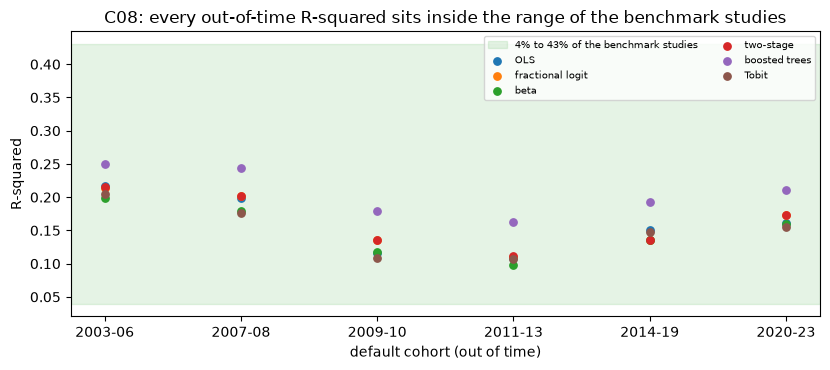

In [5]:
# Draw the out-of-time R-squared of every rung and cohort against the interval of the benchmark studies
points = [(i, r["r2"], r["rung_id"]) for i, c in enumerate(COHORTS) for r in c08[c]["outputs"]["rung_comparison"]]
all_r2 = [p[1] for p in points]
print(f"R-squared over {len(all_r2)} rung-cohort scores: minimum {min(all_r2):.4f} | maximum {max(all_r2):.4f}")
fig, ax = plt.subplots(figsize=(8.4, 3.8))
ax.axhspan(0.04, 0.43, color="tab:green", alpha=0.12, label="4% to 43% of the benchmark studies")
for rung_id, label in short.items():
    mine = [p for p in points if p[2] == rung_id]
    ax.scatter([p[0] for p in mine], [p[1] for p in mine], label=label, s=28)
ax.set_xticks(range(len(COHORTS)))
ax.set_xticklabels(COHORTS)
ax.set_xlabel("default cohort (out of time)")
ax.set_ylabel("R-squared")
ax.set_title("C08: every out-of-time R-squared sits inside the range of the benchmark studies")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

All thirty-six points lie inside the green band, and none comes near its upper end: the best out-of-time R-squared is about 0.25 against a ceiling of 0.43 in the studies, and the worst is about 0.10 against a floor of 0.04. Within a cohort the rungs sit close together and one rung, the boosted trees, rides above the rest in every cohort, a pattern the next steps examine. The cohorts themselves matter as much as the rungs: the cloud falls from 2003-06 to 2011-13 and recovers afterwards, so a single R-squared hides how much the era of the defaults changes the apparent skill of a model.

### Non-linear against linear, run on a known truth

The benchmark statement is that non-linear methods beat linear ones when over-fitting is controlled. On C08 the real loans are not committed, so the comparison cannot be refitted there; the committed scores are checked in the next sections. To run the statement itself the notebook generates a sample whose mean function is known and has an interaction that a main-effects model cannot represent, fits the engine's linear and two-stage rungs on one half and scores them on the other half. The first cell fits and scores the engine's rungs.

In [6]:
# Generate a sample with a known interaction and fit the engine's linear rungs on the first half
rng = np.random.default_rng(20261028)
n = 8000
z = rng.normal(size=(n, 3))
mu = 1 / (1 + np.exp(-(0.2 + 1.3 * z[:, 0] * z[:, 1] - 0.9 * (z[:, 2] > 0.3))))
body = rng.beta(mu * 4.0, (1 - mu) * 4.0)
y = np.where(rng.random(n) < 0.15, 0.0, np.where(rng.random(n) < 0.08, 1.0, body))
X = np.column_stack([np.ones(n), z])
train, hold = slice(0, n // 2), slice(n // 2, n)
rungs = {"OLS": lm.fit_ols(X[train], y[train]), "fractional logit": lm.fit_fractional_logit(X[train], y[train]),
         "two-stage": lm.fit_hurdle(X[train], y[train])}
pred = {name: lm.predict_lgd(fit, X[hold]) for name, fit in rungs.items()}
print(f"held-out mean realised LGD: {y[hold].mean():.4f}")
for name, p in pred.items():
    r2 = 1 - np.sum((y[hold] - p) ** 2) / np.sum((y[hold] - y[hold].mean()) ** 2)
    print(f"{name:20s} R-squared {r2:7.4f} | calibration gap {y[hold].mean() - p.mean():+.4f}")

held-out mean realised LGD: 0.4371
OLS                  R-squared  0.0256 | calibration gap +0.0090
fractional logit     R-squared  0.0255 | calibration gap +0.0090
two-stage            R-squared  0.0260 | calibration gap +0.0089


The reference implementation is scikit-learn's `GradientBoostingRegressor`, pinned in `notebooks/requirements.txt`: 200 trees of depth 3 on the same half, scored on the other half with the same two measures. It stands for the non-linear family of the studies (the engine itself keeps its boosted rung in the pipeline, not in the package).

In [7]:
# Fit gradient-boosted trees as the reference and score them like the engine's rungs
boost = GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=0)
boost.fit(z[train], y[train])
pred["boosted trees (reference)"] = np.clip(boost.predict(z[hold]), 0.0, 1.0)
scores = {}
for name, p in pred.items():
    r2 = 1 - np.sum((y[hold] - p) ** 2) / np.sum((y[hold] - y[hold].mean()) ** 2)
    scores[name] = (r2, y[hold].mean() - p.mean())
    print(f"{name:34s} R-squared {r2:7.4f} | calibration gap {scores[name][1]:+.4f}")

OLS                                R-squared  0.0256 | calibration gap +0.0090
fractional logit                   R-squared  0.0255 | calibration gap +0.0090
two-stage                          R-squared  0.0260 | calibration gap +0.0089
boosted trees (reference)          R-squared  0.2077 | calibration gap +0.0054


The next cell draws the two scores side by side, discrimination on the left and calibration on the right, for the three engine rungs and the reference.

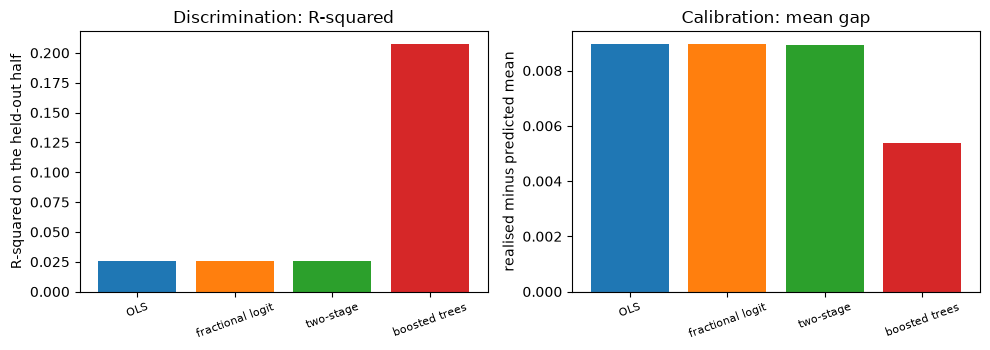

In [8]:
# Draw the R-squared and the calibration gap of each model on the held-out half
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
names = list(scores)
left.bar(range(len(names)), [scores[k][0] for k in names], color=["tab:blue", "tab:orange", "tab:green", "tab:red"])
right.bar(range(len(names)), [scores[k][1] for k in names], color=["tab:blue", "tab:orange", "tab:green", "tab:red"])
ylabels = ("R-squared on the held-out half", "realised minus predicted mean")
for ax, ylabel in zip((left, right), ylabels):
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels([k.split(" (")[0] for k in names], rotation=20, fontsize=8)
    ax.set_ylabel(ylabel)
right.axhline(0.0, color="grey", linewidth=0.8)
left.set_title("Discrimination: R-squared")
right.set_title("Calibration: mean gap")
fig.tight_layout()
plt.show()

On a truth that contains an interaction the non-linear model wins on R-squared by a wide margin, which is the benchmark statement in its clean form; the three linear and two-stage rungs are tied and low because none can represent the product of the first two covariates. The right panel is the reminder of the studies' takeaway: the gains in R-squared say nothing about the level, and each model has its own calibration gap, small here for all four. On C08 the gap is not small, which is why the committed cohorts are examined next.

The engine's own tests judge the same four models on the held-out half. `lgd_calibration_by_segment` is the paired t-test of the mean gap and `lgd_discrimination` the Spearman correlation against fixed gates, the two tests that notebook 06 computes by hand and that the committed C08 rows report; the cell prints their p-value, correlation and lights.

In [9]:
# Run the engine's calibration and discrimination tests on the four models of the held-out half
for name, p in pred.items():
    seg = tests.lgd_calibration_by_segment(y[hold], p, segment=name)
    order = tests.lgd_discrimination(y[hold], p, segment=name)
    left = f"{name:34s} calibration p={seg.p_value:.3g} {light[seg.light.value]:8s}"
    print(left, f"| Spearman {order.statistic:.4f} {light[order.light.value]}")

OLS                                calibration p=0.1 green    | Spearman 0.1563 amber
fractional logit                   calibration p=0.0996 green    | Spearman 0.1563 amber
two-stage                          calibration p=0.101 green    | Spearman 0.1573 amber
boosted trees (reference)          calibration p=0.275 green    | Spearman 0.4078 green


### Two more non-linear rungs: a random forest and a neural network

Bellotti, Brigo, Gambetti and Vrins (2021) compared twenty techniques on record-level recovery data and found rule ensembles
(Cubist), Gaussian processes and random forests ahead of the linear models. The product's LGD ladder therefore goes beyond one
boosted model with two more machine-learning families, as rungs L7 and L8 (`pipeline.cases.c08.ml_benchmark`): scikit-learn's `RandomForestRegressor` with squared-error splits and
leaves of at least 30 loans, and an `MLPRegressor` with two hidden layers of 32 and 16 units and early stopping on a tenth of the
training span, both fixed before any test cohort was seen. The next cell fits the two rungs, with the product's own settings, on
the same half of the sample with a known interaction that the boosted trees learned above, and scores them on the same held-out
half.

In [ ]:
# Fit the pipeline's two new rungs, the random forest and the neural network, on the same half and score them
import warnings

from sklearn.exceptions import ConvergenceWarning

from pipeline.cases.c08 import ml_benchmark as ml

forest = ml.fit_forest(z[train], y[train], 7)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    network = ml.fit_network(z[train], y[train], 7)
pred["random forest (L7)"] = ml.predict(forest, z[hold])
pred["neural network (L8)"] = ml.predict(network, z[hold])
epochs_label = "network epochs"
gap_label = "calibration gap"
print(f"{epochs_label}: {network.n_iter_} / {network.max_iter}")
for name in ("fractional logit", "boosted trees (reference)", "random forest (L7)", "neural network (L8)"):
    p = pred[name]
    r2 = 1 - np.sum((y[hold] - p) ** 2) / np.sum((y[hold] - y[hold].mean()) ** 2)
    rmse = np.sqrt(np.mean((y[hold] - p) ** 2))
    print(f"{name:28s} R2 {r2:.4f} | RMSE {rmse:.4f} | {gap_label} {y[hold].mean() - p.mean():+.4f}")


On the known interaction the neural network is the best of the four: an R-squared of 0.2249 and an RMSE of 0.3074
against 0.2077 and 0.3108 for the boosted trees, while the random forest, at 0.1709, sits between the boosted trees and the
fractional logit (0.0255). The network stops at the end of its epoch budget, which the cell prints, so it has not converged in the
optimiser's sense; the product keeps that budget because the hold-out loss had stopped improving. The question for the product is
whether this ordering survives on the real charge-offs, cohort by cohort, out of time. The next figure reads the committed
comparison of the six default cohorts of case C08.

In [ ]:
# Draw the out-of-time RMSE of each cohort: the best linear rung, the boosted trees and the two new rungs
linear = ("L1-ols", "L2-fractional-logit", "L3-beta", "L4-hurdle", "L6-tobit")
series = {"best linear": [], "L5-gradient-boosted": [], "L7-random-forest": [], "L8-neural-network": []}
outcomes = []
for c in COHORTS:
    rows = c08[c]["outputs"]["rung_comparison"]
    rc = {r["rung_id"]: r["rmse"] for r in rows}
    series["best linear"].append(min(rc[k] for k in linear if k in rc))
    for k in ("L5-gradient-boosted", "L7-random-forest", "L8-neural-network"):
        series[k].append(rc[k])
    outcomes.append(ml.cohort_result(rows))
fig, ax = plt.subplots(figsize=(8.4, 3.8))
for k, v in series.items():
    ax.plot(COHORTS, v, marker="o", label=k)
ax.set_xlabel("default cohort of the test")
ax.set_ylabel("out-of-time RMSE of the LGD")
ax.set_title("The new rungs against the boosted trees, cohort by cohort")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for c, o in zip(COHORTS, outcomes):
    print(f"{c}: {o['classical'][0]} {o['classical'][1]:.4f} | {o['ml'][0]} {o['ml'][1]:.4f} | {o['gain']:+.4f}")
wins = sum(o["ml_wins"] for o in outcomes)
wins_label = "cohorts where the better new rung beats the six before it"
print(f"{wins_label}: {wins} / {len(COHORTS)} -> {ml.verdict(wins, len(COHORTS))}")


The four lines run almost on top of each other in every cohort: the out-of-time RMSE moves from about 0.275 to 0.33
with the cohort, and the gap between the best and the worst of the four non-linear and linear choices is a few thousandths. The
better of the two new rungs beats the boosted trees in two cohorts, 2003-06 by 0.0001 and 2014-19 by 0.0005, and loses in the
other four, so the hypothesis fixed before the run, that the new rungs improve on the six before them in at least two thirds of the cohorts, is
refuted by the product's own rule. On a sample with a strong interaction the network wins; on the charge-off records, whose
signal is weak, the extra flexibility buys nothing that the boosted trees did not already have.

### Non-linear against linear, and fractional against OLS

Two statements to check on the derived quantities of step 1. Non-parametric (non-linear) methods beat parametric ones when over-fitting is controlled: here the boosted trees against the fractional logit, by R-squared gain and by the rung with the highest Spearman correlation in each cohort. And fractional response regression has a slight edge over OLS: here the R-squared and RMSE difference between the two, which the cell counts across cohorts. A caution about reading them: the boosted trees have 200 trees of depth 6 fitted once on data up to the cutoff, and the cohorts are out of time, so over-fitting is controlled in the sense of the test design; the notebook does not tune anything.

In [10]:
# Count the cohorts where each statement holds, from the quantities derived in step 1
gains = [d["gain"] for d in derived.values()]
print(f"R-squared gain of boosted trees over the fractional logit: {min(gains):+.4f} to {max(gains):+.4f}")
print(f"positive in {sum(g > 0 for g in gains)} of {len(COHORTS)} cohorts")
best = {c: short[d["best_sp"]] for c, d in derived.items()}
print("rung with the highest Spearman correlation:", sorted(set(best.values())))
d_r2 = [d["d_r2"] for d in derived.values()]
d_rmse = [d["d_rmse"] for d in derived.values()]
print(f"fractional logit minus OLS, R-squared: {['%+.4f' % x for x in d_r2]}")
better = sum(x > 0 for x in d_r2)
lower = sum(x < 0 for x in d_rmse)
print(f"R-squared higher in {better} of {len(COHORTS)} | RMSE lower in {lower} of {len(COHORTS)}")
print(f"largest absolute difference: R-squared {max(map(abs, d_r2)):.4f}, RMSE {max(map(abs, d_rmse)):.4f}")

R-squared gain of boosted trees over the fractional logit: +0.0355 to +0.0576
positive in 6 of 6 cohorts
rung with the highest Spearman correlation: ['boosted trees']
fractional logit minus OLS, R-squared: ['-0.0023', '+0.0029', '+0.0192', '+0.0016', '-0.0150', '+0.0118']
R-squared higher in 4 of 6 | RMSE lower in 4 of 6
largest absolute difference: R-squared 0.0192, RMSE 0.0034


### The beta model and its endpoint adjustment

Qi and Zhao found the beta (and inverse Gaussian) models very sensitive to the small number used to move values at 0 and 1 inside the open interval. C08 reports that sensitivity for the beta rung in each cohort (`endpoint_sensitivity`). To judge whether the sensitivity matters, the cell compares the range of the mean prediction over the three adjustments with the difference in calibration gap between the beta rung and the fractional logit, which is the size of the choice of model family. When the first is larger, the choice of the adjustment moves the level of the model more than the choice between those two families does.

In [11]:
# Refit the beta rung at three values of epsilon on the sample with a known interaction
print(f"held-out realised mean: {y[hold].mean():.4f}")
for eps in (0.0001, 0.001, 0.01):
    fit = lm.fit_beta(X[train], y[train], eps)
    mean_p = lm.predict_lgd(fit, X[hold]).mean()
    print(f"epsilon={eps:<7} mean prediction {mean_p:.4f} | gap {y[hold].mean() - mean_p:+.4f}")

held-out realised mean: 0.4371
epsilon=0.0001  mean prediction 0.4270 | gap +0.0102
epsilon=0.001   mean prediction 0.4312 | gap +0.0059
epsilon=0.01    mean prediction 0.4375 | gap -0.0004


On the sample whose truth is known the beta rung's level moves with the small number, as the studies found: its gap runs from +0.0102 to -0.0004 over the three values, a range of about 0.0105, as large as the +0.0090 gap of the linear rungs. The committed cohorts of C08 give the same comparison on the real indicator, in the next cell.

In [12]:
# Compare the range of the beta rung's mean prediction over epsilon with the calibration-gap difference
print(f"{'cohort':8s} {'range over epsilon':>24s} {'gap difference':>24s} {'epsilon larger':>16s}")
bigger = 0
for c, d in derived.items():
    bigger += d["eps_range"] > d["gap_diff"]
    print(f"{c:8s} {d['eps_range']:24.4f} {d['gap_diff']:24.4f} {d['eps_range'] > d['gap_diff']!s:>16}")
print(f"cohorts where the endpoint adjustment moves the level more than the family: {bigger} of {len(COHORTS)}")

cohort         range over epsilon           gap difference   epsilon larger
2003-06                    0.0057                   0.0123            False
2007-08                    0.0166                   0.0145             True
2009-10                    0.0234                   0.0142             True
2011-13                    0.0147                   0.0067             True
2014-19                    0.0016                   0.0026            False
2020-23                    0.0100                   0.0011             True
cohorts where the endpoint adjustment moves the level more than the family: 4 of 6


### Calibration and R-squared

The takeaway of the research is that the evaluation must include calibration and not only R-squared. Across the rungs of one cohort, does a higher R-squared go with a smaller calibration gap? The cell prints the rank correlation computed in step 1 (negative means yes) and whether the rung with the highest R-squared is also the one with the smallest absolute gap in each cohort.

In [13]:
# Print the rank correlation of R-squared with the gap and whether the highest R-squared is the smallest gap
same = 0
for c in COHORTS:
    rc = {r["rung_id"]: r for r in c08[c]["outputs"]["rung_comparison"]}
    top_r2 = max(rc, key=lambda k: rc[k]["r2"])
    top_gap = min(rc, key=lambda k: abs(rc[k]["calibration_gap"]))
    same += top_r2 == top_gap
    print(f"{c:8s} rank correlation {derived[c]['rho']:+.3f} | {short[top_r2]:>20s} | {short[top_gap]:>20s}")
print(f"the rung with the highest R-squared also has the smallest gap in {same} of {len(COHORTS)}")

2003-06  rank correlation -0.886 |        boosted trees |                  OLS
2007-08  rank correlation -0.771 |        boosted trees |        boosted trees
2009-10  rank correlation -0.714 |        boosted trees |     fractional logit
2011-13  rank correlation -0.200 |        boosted trees |            two-stage
2014-19  rank correlation +0.371 |        boosted trees |                  OLS
2020-23  rank correlation -0.829 |        boosted trees |        boosted trees
the rung with the highest R-squared also has the smallest gap in 2 of 6


### EAD: factor models against a direct model

For exposure at default, Tong et al. (2016) compare direct EAD models with CCF variants and a utilisation-change model on UK card data and find the zero-adjusted gamma direct model more accurate in calibration. Contraste cannot reproduce that comparison, because its direct model is a fractional logit and not a zero-adjusted gamma mixture (the engine's docstring says so). What it can show is the same three families on the C09 generator through the engine's back-test: the table of step 2 and a figure of the metric by level.

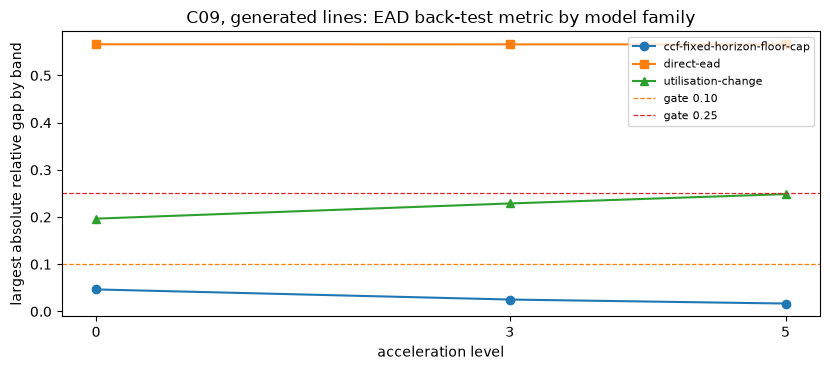

level 0: direct model, worst band [1.5, 4.0) -0.5661
level 3: direct model, worst band [1.5, 4.0) -0.5659
level 5: direct model, worst band [1.5, 4.0) -0.5658


In [14]:
# Draw the back-test metric of the three EAD families at the three levels, with the green and red gates
fig, ax = plt.subplots(figsize=(8.4, 3.8))
for family, marker in zip(families, ("o", "s", "^")):
    ax.plot([0, 3, 5], [ead[(level, family)].metric for level in (0, 3, 5)], marker=marker, label=family)
ax.axhline(0.10, color="tab:orange", linestyle="--", linewidth=0.9, label="gate 0.10")
ax.axhline(0.25, color="tab:red", linestyle="--", linewidth=0.9, label="gate 0.25")
ax.set_xticks([0, 3, 5])
ax.set_xlabel("acceleration level")
ax.set_ylabel("largest absolute relative gap by band")
ax.set_title("C09, generated lines: EAD back-test metric by model family")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for level in (0, 3, 5):
    worst = max(ead[(level, "direct-ead")].extras["bands"], key=lambda band: abs(band["relative_gap"] or 0.0))
    edge = f"[{worst['lower']}, {worst['upper']})"
    print(f"level {level}: direct model, worst band {edge} {worst['relative_gap']:+.4f}")

The factor model sits under the green gate at all three levels, the utilisation-change model above it and climbing with the acceleration, and the direct model far above the red gate at every level, with its worst band the same one each time, the lines over their limit, printed beneath the figure. The ordering is stable because it comes from how each model is built and not from the acceleration: the direct model cannot exceed the limit, the utilisation-change model is unbounded and over-reads lines near the limit, and the factor model applies a share to whatever undrawn amount a line has. This is the benchmark question put to the engine's models, with a verdict that depends on the metric and on the data.

## Results

**Answer:** Mostly yes, with two limits. On a sample with a known interaction the boosted trees reach an out-of-sample R-squared of 0.2077 against 0.0255 for the fractional logit and 0.0256 for OLS, the non-linear gain of the studies in its clean form. On the six C08 cohorts the 36 rung-cohort R-squared scores run from 0.0975 to 0.2497, inside the 4% to 43% of the studies, and the boosted trees lead the fractional logit by 0.0355 to 0.0576 in 6 of 6 cohorts; the first limit is that the rung with the highest R-squared has the smallest calibration gap in only 2 of 6. The second is the EAD: on generated lines the factor model is green (0.0466 at level 0, 0.0252 at level 3), the utilisation-change model amber (0.1966 to 0.2486) and the direct model red (0.5658 to 0.5661).

- **R-squared is low and inside the benchmark range.** Over the 36 rung-cohort scores of C08 the R-squared runs from 0.0975 to 0.2497, inside the 4% to 43% interval the benchmark studies report.
- **Non-linear beats linear.** On the known-interaction sample the boosted trees score 0.2077 and the linear and two-stage rungs 0.0255, 0.0256 and 0.0260; on C08 the boosted trees gain 0.0355 to 0.0576 of R-squared over the fractional logit in all six cohorts and have the highest Spearman correlation in all six, with the caveat that the target is an indicator with a stated bias.
- **The engine's tests agree on the known truth.** On the held-out half the calibration light is green for all four models (p-values from 0.0996 to 0.275) while the Spearman correlation is 0.1563 (amber) for OLS and the fractional logit, 0.1573 for the two-stage rung and 0.4078 (green) for the boosted trees; the beta rung's gap runs from +0.0102 to -0.0004 as epsilon goes from 0.0001 to 0.01.
- **The fractional logit's edge over OLS is small and mixed.** It has the higher R-squared in 4 of 6 cohorts and the lower RMSE in 4 of 6, and the largest difference is 0.0192 of R-squared and 0.0034 of RMSE, against the 0.0355 to 0.0576 gain of the boosted trees.
- **The endpoint adjustment of the beta rung matters.** The range of its mean prediction over the three adjustments runs from 0.0016 to 0.0234, and it exceeds the difference in calibration gap between the beta rung and the fractional logit in 4 of the 6 cohorts: in those, the choice of the small number moves the level more than the choice between those two families.
- **R-squared and calibration travel together only in part.** Across the rungs of a cohort the rank correlation between R-squared and the absolute gap is between -0.886 and -0.714 in three cohorts and -0.829 in 2020-23, -0.200 in 2011-13 and +0.371 in 2014-19; the highest R-squared coincides with the smallest absolute gap in 2007-08 and 2020-23 only. Calibration has to be read in its own right.
- **For EAD, the factor model passes and the direct fractional logit fails.** At levels 0, 3 and 5 the factor model scores 0.0466, 0.0252 and 0.0167 (green), the utilisation-change model 0.1966, 0.2288 and 0.2486 (amber, growing with the acceleration) and the direct model 0.5661, 0.5659 and 0.5658 (red), in the band from 1.5 to 4.0 times the limit every time, having clipped 1,709, 2,052 and 2,359 training lines.
- **What is not reproduced.** The zero-adjusted gamma direct model of Tong et al. (2016) is not in the engine, so the finding that it calibrates better than the factor models is neither confirmed nor contradicted; the zero-or-one inflated beta, the macro-conditioned and the survival models are not implemented either.

What these checks do not show: they use a charge-off indicator with a stated bias, a toy sample and a synthetic generator whose truth is defined at twelve months, so they say how the models behave on these data and do not rank them for any bank. The benchmark statements are those of the research as it recorded them from abstracts, not a review of the full papers.

The two machine-learning rungs behave as the benchmark says only where the signal is strong: on the sample with
a known interaction the neural network reaches an R-squared of 0.2249 against 0.2077 for the boosted trees, while on the six
charge-off cohorts the better new rung beats the boosted trees in 2 of 6, by at most 0.0005 of RMSE, and the hypothesis is
refuted.

## Summary

- The benchmark literature on LGD finds low R-squared everywhere, an advantage for non-linear methods, a slight one for fractional response over OLS, and a strong sensitivity of the beta model to its endpoint adjustment; for EAD it compares direct models with factor and utilisation-change models. Contraste implements OLS, fractional logit, beta, a logit-fractional two-stage model and Tobit for LGD, boosted trees in its pipeline, and the factor, direct (fractional logit) and utilisation-change models for EAD; it does not implement the zero-adjusted gamma, inflated beta, macro-conditioned or survival models.
- Run on a sample with a known interaction, boosted trees beat the linear and two-stage rungs by a wide margin of R-squared; on the six C08 cohorts the R-squared sits inside the range of the studies, the boosted trees have the highest R-squared in every cohort, the fractional logit's edge over OLS is small and mixed, and in four of the six cohorts the beta rung's level moves more with its endpoint adjustment than with the choice between it and the fractional logit.
- The rung with the highest R-squared is the best calibrated in only some cohorts, so calibration has to be judged beside the R-squared.
- On generated C09 lines the factor models pass the engine's back-test at every level, the utilisation-change model is amber or worse, and the direct fractional logit fails in the same band at every level. This does not reproduce Tong et al. (2016), whose direct model is a different one.
- All of this is about a charge-off indicator and synthetic generators, so it is a statement about the models on these data.

**What to try next.** Read the committed calibration by bucket of one cohort next to the R-squared of each rung and write down which rung you would take to a model committee, and what evidence you would still ask for. This topic has no level 4 notebook: no SDD claim rests on the LGD and EAD cases yet.

- The random forest and the neural network do not improve the out-of-time LGD of the charge-offs: the better of the two beats the boosted trees in 2 of 6 cohorts by at most 0.0005 of RMSE.

## References

- Loterman, G., Brown, I., Martens, D., Mues, C. and Baesens, B. (2012), Benchmarking regression algorithms for loss given default modeling, International Journal of Forecasting 28(1):161-170. https://doi.org/10.1016/j.ijforecast.2011.01.006
- Qi, M. and Zhao, X. (2011), Comparison of modeling methods for loss given default, Journal of Banking and Finance 35(11):2842-2855. https://doi.org/10.1016/j.jbankfin.2011.03.011
- Leow, M. and Mues, C. (2012), Predicting loss given default (LGD) for residential mortgage loans: a two-stage model and empirical evidence for UK bank data, International Journal of Forecasting 28(1):183-195. https://doi.org/10.1016/j.ijforecast.2011.01.010
- Tong, E. N. C., Mues, C. and Thomas, L. (2013), A zero-adjusted gamma model for mortgage loan loss given default, International Journal of Forecasting 29(4):548-562. https://doi.org/10.1016/j.ijforecast.2013.03.003
- Ospina, R. and Ferrari, S. L. P. (2012), A general class of zero-or-one inflated beta regression models, Computational Statistics and Data Analysis 56(6):1609-1623. https://doi.org/10.1016/j.csda.2011.10.005
- Bellotti, T. and Crook, J. (2012), Loss given default models incorporating macroeconomic variables for credit cards, International Journal of Forecasting 28(1):171-182. https://doi.org/10.1016/j.ijforecast.2010.08.005
- Tong, E. N. C., Mues, C., Brown, I. and Thomas, L. C. (2016), Exposure at default models with and without the credit conversion factor, European Journal of Operational Research 252(3):910-920. https://doi.org/10.1016/j.ejor.2016.01.054
- Leow, M. and Crook, J. (2013), Estimation of credit card exposure at default (EAD), working paper, University of Edinburgh Credit Research Centre (as recorded in the research dossier; read pp. 1 to 5).
- BCBS, Basel Framework, CRE32. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- The research dossier of this product on credit risk models (sections on LGD and on EAD and CCF), which records the findings above from abstracts and search summaries, and the engine's documentation of `fit_direct_ead` (release 0.8.1).
- This repository: `docs/design/SDD.md` (cases C08 and C09) and `data/derived/C08/`, `data/derived/C09/`.

- Bellotti, A., Brigo, D., Gambetti, P. and Vrins, F. (2021), Forecasting recovery rates on non-performing loans with machine learning, International Journal of Forecasting 37(1), 428-444, https://doi.org/10.1016/j.ijforecast.2020.06.009